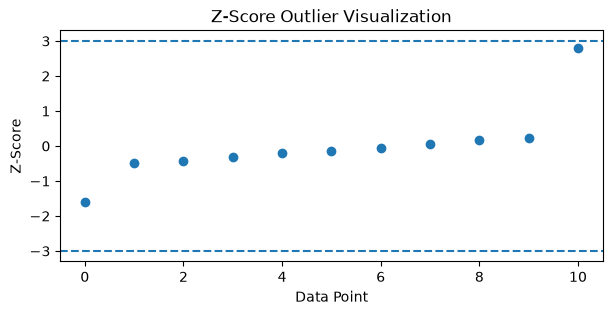

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

#finding the z-score and outliers in a dataset using z-score

data = np.array([-20, 10, 12, 15, 18, 20, 22, 25, 28, 30, 100])
z_scores = zscore(data)

plt.figure(figsize=(7,3))
plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle = "--")
plt.axhline(-3, linestyle = "--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

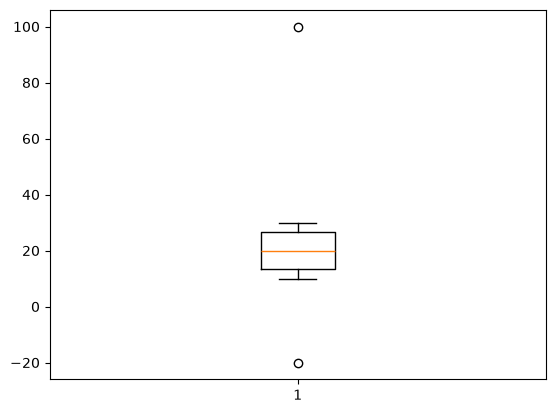

In [2]:
plt.boxplot(data)
plt.show()

In [3]:
import seaborn as sns
import pandas as pd

In [4]:
df = sns.load_dataset("tips")

In [5]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


{'whiskers': [<matplotlib.lines.Line2D at 0x1f8fb6f78c0>,
 'caps': [<matplotlib.lines.Line2D at 0x1f8fb6f7b60>,
 'boxes': [<matplotlib.lines.Line2D at 0x1f8fb6f7770>],
 'medians': [<matplotlib.lines.Line2D at 0x1f8fb6f7e00>],
 'fliers': [<matplotlib.lines.Line2D at 0x1f8fb890050>],
 'means': []}

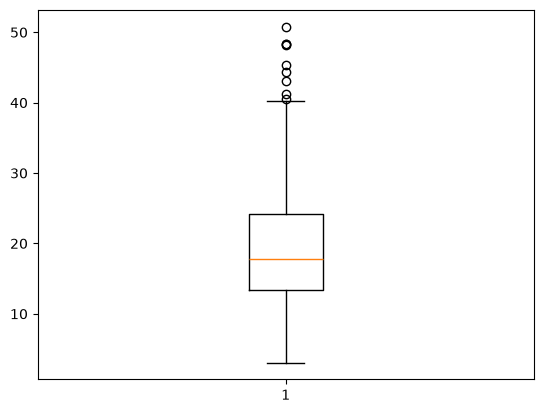

In [6]:
plt.boxplot(df['total_bill'])

In [7]:
Q1 = df['total_bill'].quantile(0.25)
Q3 = df['total_bill'].quantile(0.75)

IQR = Q3 - Q1

print(f"IQR: {IQR}")

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound}, \nUpper Bound: {upper_bound}")

IQR: 10.779999999999998
Lower Bound: -2.8224999999999945, 
Upper Bound: 40.29749999999999


In [8]:
#filtering the outliers using IQR method
df = df[(df['total_bill'] > lower_bound) & (df['total_bill'] < upper_bound)]

{'whiskers': [<matplotlib.lines.Line2D at 0x1f8fb8923c0>,
 'caps': [<matplotlib.lines.Line2D at 0x1f8fb892660>,
 'boxes': [<matplotlib.lines.Line2D at 0x1f8fb892270>],
 'medians': [<matplotlib.lines.Line2D at 0x1f8fb892900>],
 'fliers': [<matplotlib.lines.Line2D at 0x1f8fb892a50>],
 'means': []}

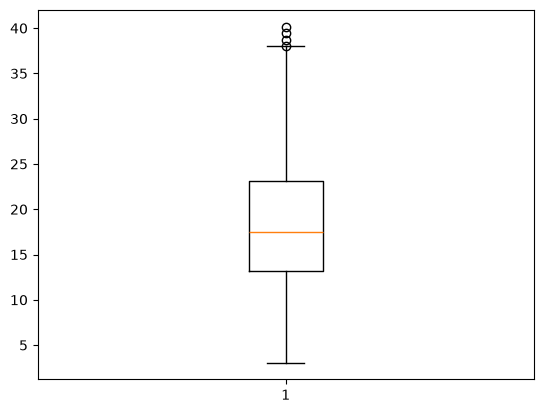

In [9]:
plt.boxplot(df['total_bill'])

{'whiskers': [<matplotlib.lines.Line2D at 0x1f8fb90a120>,
 'caps': [<matplotlib.lines.Line2D at 0x1f8fb90a3c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1f8fb909fd0>],
 'medians': [<matplotlib.lines.Line2D at 0x1f8fb90a660>],
 'fliers': [<matplotlib.lines.Line2D at 0x1f8fb90a7b0>],
 'means': []}

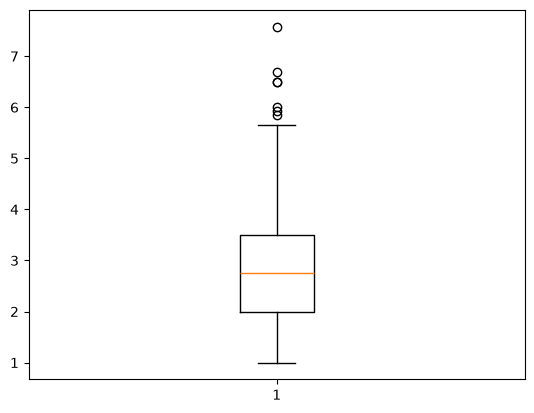

In [10]:
plt.boxplot(df['tip'])

In [11]:
Q1 = df['tip'].quantile(0.25)
Q3 = df['tip'].quantile(0.75)

IQR = Q3 - Q1

print(f"IQR: {IQR}")

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


print(f"Lower Bound: {lower_bound}, \nUpper Bound: {upper_bound}")

IQR: 1.5
Lower Bound: -0.25, 
Upper Bound: 5.75


{'whiskers': [<matplotlib.lines.Line2D at 0x1f8fb971a90>,
 'caps': [<matplotlib.lines.Line2D at 0x1f8fb971d30>,
 'boxes': [<matplotlib.lines.Line2D at 0x1f8fb971940>],
 'medians': [<matplotlib.lines.Line2D at 0x1f8fb971fd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1f8fb972120>],
 'means': []}

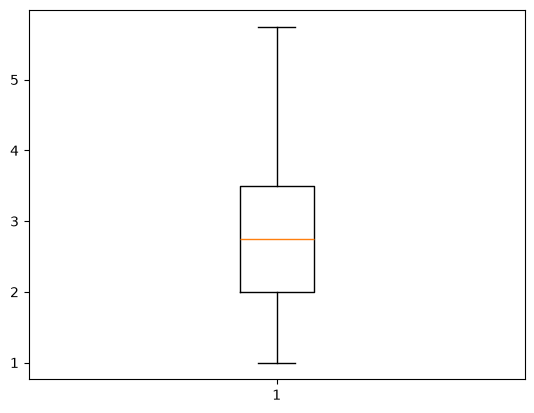

In [12]:
df['tip'] = df['tip'].clip(upper=upper_bound)
plt.boxplot(df['tip'])

In [13]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

In [14]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [15]:
num_fea=['total_bill']
ohe_fea=['sex', 'smoker']
min_max=['tip']

In [16]:
transformer=ColumnTransformer(
transformers=[('num', StandardScaler(), num_fea),
('min_max', MinMaxScaler(), min_max),
('cat', OneHotEncoder(), ohe_fea),
], remainder='passthrough'
)

In [17]:
transformer.fit_transform(df)

array([[-0.2436713240621389, 0.002105263157894749, 1.0, ..., 'Sun',
        'Dinner', 2],
       [-1.1395807953545036, 0.1389473684210526, 0.0, ..., 'Sun',
        'Dinner', 3],
       [0.29791605557625356, 0.5263157894736842, 0.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.5215566153274304, 0.21052631578947367, 0.0, ..., 'Sat',
        'Dinner', 2],
       [-0.13185104418655025, 0.15789473684210525, 0.0, ..., 'Sat',
        'Dinner', 2],
       [-0.002516744571411735, 0.42105263157894735, 1.0, ..., 'Thur',
        'Dinner', 2]], shape=(235, 9), dtype=object)

In [18]:
pd.DataFrame(transformer.fit_transform(df), columns=transformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Female,cat__sex_Male,cat__smoker_No,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.243671,0.002105,1.0,0.0,1.0,0.0,Sun,Dinner,2
1,-1.139581,0.138947,0.0,1.0,1.0,0.0,Sun,Dinner,3
2,0.297916,0.526316,0.0,1.0,1.0,0.0,Sun,Dinner,3
3,0.657627,0.486316,0.0,1.0,1.0,0.0,Sun,Dinner,2
4,0.780225,0.549474,1.0,0.0,1.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...,...,...
230,1.378396,1.0,0.0,1.0,1.0,0.0,Sat,Dinner,3
231,1.129158,0.210526,1.0,0.0,0.0,1.0,Sat,Dinner,2
232,0.521557,0.210526,0.0,1.0,0.0,1.0,Sat,Dinner,2
233,-0.131851,0.157895,0.0,1.0,1.0,0.0,Sat,Dinner,2
